# 11 · Nearest neighbours combined with popularity (work package 3, core problem 1)

**Work package 3** of the [implementation plan](../../research/implementation_plan.md). The model is the fixed
combination of the project plan (section 6.1):

$$\text{score}(u, i) = w\,\tilde p_i + (1 - w)\,\tilde r_{ui}$$

- $p_i$: the number of accounts that traded token $i$ in the 14 days before $t$ (the baseline's popularity),
- $r_{ui} = \sum_{j \in H_u} s_{ji}$: how similar $i$ is to the tokens $H_u$ the account traded, where $s_{ji}$ is the
  cosine of the two tokens' account sets with shrinkage $\lambda$, and only the $k$ most similar tokens of each
  token are kept,
- the tilde scales each score to a maximum of 1 per account.

With $w = 1$ this is exactly the baseline, with $w = 0$ it is neighbours alone.

**Procedure.** The settings $k$, $\lambda$ and $w$ are chosen on the 10 **Dev A** points only. The chosen model is
then compared with the baseline on the 11 **Dev B** points, which played no part in the choice.

In [1]:
import json
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import pandas as pd

import plots
import protocol as pc
import stats
import token_data as td
import tuning

plots.style()
pd.set_option("display.float_format", "{:,.4f}".format)
OUT = pc.RESULTS_DIR / "wp3"
OUT.mkdir(parents=True, exist_ok=True)
CONFIG = pc.RESULTS_DIR.parent / "configs" / "wp3_knn.json"

legs = td.load_legs()

## 1. The grid, evaluated on Dev A

| Setting | Values |
| --- | --- |
| $k$ (neighbours kept per token) | 10, 25, 50, 100, 200 |
| $\lambda$ (shrinkage) | 0, 1, 5, 10, 25, 50 |
| $w$ (weight of popularity) | 0, 0.1, …, 1.0 |

330 settings × 10 points. `tuning.blend_grid` computes the neighbour scores once per ($k$, $\lambda$) and reuses
them for every $w$; a test checks that it gives exactly the recall of `protocol.run` with `pool_recsys.Blend`.
The grid takes a while, so its result is saved and read back when the notebook is run again.

In [2]:
KS = [10, 25, 50, 100, 200]
SHRINKS = [0, 1, 5, 10, 25, 50]
WEIGHTS = [round(0.1 * i, 1) for i in range(11)]
GRID_FILE = OUT / "grid_dev_a.csv"

if GRID_FILE.exists():
    grid = pd.read_csv(GRID_FILE, parse_dates=["point"])
    print(f"Read {len(grid):,} rows from {GRID_FILE.name}")
else:
    parts = []
    for t in pc.POINTS["dev_a"]:
        task = pc.load_task(legs, t)
        window = task.history(pc.REFERENCE_DAYS)
        parts.append(tuning.blend_grid(task, window, window, KS, SHRINKS, WEIGHTS))
        print(f"  {t:%d %b}: done ({len(task.eval_rows):,} accounts)", flush=True)
    grid = pd.concat(parts, ignore_index=True)
    grid.to_csv(GRID_FILE, index=False)

Read 3,300 rows from grid_dev_a.csv


### The grid extended

On the planned grid the best setting was $k = 200$, $\lambda = 50$: the largest value of both, with recall still
rising towards that edge (+0.005 from $k$ = 100 to 200, +0.004 from $\lambda$ = 25 to 50). The best setting could
therefore lie outside the grid, so the grid is extended by $k$ = 400, 800 and $\lambda$ = 100, 200 (a change to
the plan, recorded in `project_direction.md`). Only the new combinations are computed:

- the new $\lambda$ values with every $k$,
- the new $k$ values with the planned $\lambda$ values.

The full grid is then 7 × 8 × 11 = 616 settings. Each point is saved as it finishes, so a stopped run resumes.

In [3]:
KS_MORE = [400, 800]
SHRINKS_MORE = [100, 200]
EXTENSION_DIR = OUT / "grid_dev_a_extension"
EXTENSION_DIR.mkdir(exist_ok=True)


def extension_for_point(t: pd.Timestamp) -> pd.DataFrame:
    """The new grid combinations at one Dev A point, read from disk if already computed."""
    point_file = EXTENSION_DIR / f"{t:%Y-%m-%d}.csv"
    if point_file.exists():
        return pd.read_csv(point_file, parse_dates=["point"])
    task = pc.load_task(legs, t)
    window = task.history(pc.REFERENCE_DAYS)
    new_shrinks = tuning.blend_grid(task, window, window, KS + KS_MORE, SHRINKS_MORE, WEIGHTS)
    new_ks = tuning.blend_grid(task, window, window, KS_MORE, SHRINKS, WEIGHTS)
    part = pd.concat([new_shrinks, new_ks], ignore_index=True)
    part.to_csv(point_file, index=False)
    print(f"  {t:%d %b}: done ({len(task.eval_rows):,} accounts)", flush=True)
    return part


extension = pd.concat([extension_for_point(t) for t in pc.POINTS["dev_a"]], ignore_index=True)
grid = pd.concat([grid, extension], ignore_index=True)
assert not grid.duplicated(["point", "k", "shrink", "weight"]).any(), "a setting was computed twice"
assert len(grid) == 10 * 7 * 8 * 11, f"expected 6,160 rows, got {len(grid):,}"
print(f"Full grid: {len(grid):,} rows ({len(grid) // 10} settings × 10 points)")

Full grid: 6,160 rows (616 settings × 10 points)


Mean recall@10 on Dev A for each $k$ and $\lambda$, at the best weight $w$ of each. The planned grid is the top-left
5 × 6 block.

In [4]:
best_per_pair = grid.groupby(["k", "shrink", "weight"])["recall"].mean().groupby(["k", "shrink"]).max()
best_per_pair.unstack("shrink")

shrink,0,1,5,10,25,50,100,200
k,,,,,,,,
10,0.1498,0.1507,0.1527,0.1545,0.1570,0.1602,0.1634,0.1697
25,0.1561,0.1568,0.1594,0.1611,0.1649,0.1680,0.1732,0.1777
50,0.1657,0.1666,0.1687,0.1698,0.1735,0.1771,0.1822,0.1873
100,0.1729,0.1738,0.1763,0.1780,0.1821,0.1857,0.1923,0.1959
200,0.1763,0.1775,0.1805,0.1826,0.1863,0.1904,0.1964,0.2004
400,0.1797,0.1805,0.1838,0.1859,0.1900,0.1942,0.2002,0.2031
800,0.1822,0.1837,0.1871,0.1896,0.1941,0.1970,0.2007,0.2011


Mean recall@10 over the 10 Dev A points for every setting; the 10 best:

In [5]:
mean = grid.groupby(["k", "shrink", "weight"], as_index=False)[["recall", "recall_1", "recall_2-4", "recall_5+"]].mean()
mean.sort_values("recall", ascending=False).head(10)

,k,shrink,weight,recall,recall_1,recall_2-4,recall_5+
520,400,200,0.3000,0.2031,0.2734,0.2257,0.1357
522,400,200,0.5000,0.2017,0.2767,0.2268,0.1323
610,800,200,0.5000,0.2011,0.2764,0.2267,0.1313
599,800,100,0.5000,0.2007,0.2719,0.2243,0.1340
608,800,200,0.3000,0.2005,0.2737,0.2164,0.1359
432,200,200,0.3000,0.2004,0.2686,0.2203,0.1358
511,400,100,0.5000,0.2002,0.2696,0.2233,0.1347
434,200,200,0.5000,0.2000,0.2730,0.2235,0.1327
609,800,200,0.4000,0.2000,0.2696,0.2223,0.1351
521,400,200,0.4000,0.2000,0.2680,0.2220,0.1361


How recall depends on the weight $w$, for the best $k$ and $\lambda$. The left end is neighbours alone, the right
end the baseline.

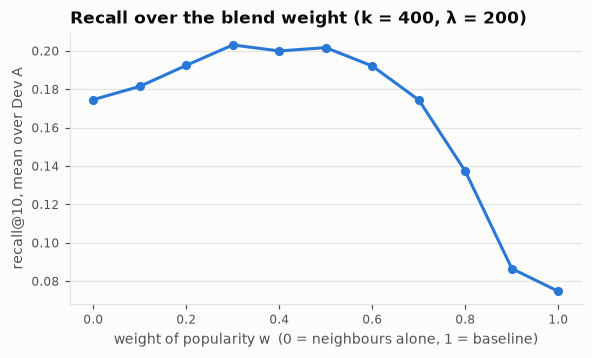

,517,518,519,520,521,522,523,524,525,526,527
weight,0.0000,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.0000
recall,0.1746,0.1815,0.1925,0.2031,0.2000,0.2017,0.1921,0.1744,0.1372,0.0865,0.0747


In [6]:
best_k, best_shrink = mean.sort_values("recall", ascending=False).iloc[0][["k", "shrink"]]
curve = mean[(mean["k"] == best_k) & (mean["shrink"] == best_shrink)]

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(curve["weight"], curve["recall"], marker="o", color=plots.colour("fixed blend"))
ax.set_xlabel("weight of popularity w  (0 = neighbours alone, 1 = baseline)")
ax.set_ylabel("recall@10, mean over Dev A")
ax.set_title(f"Recall over the blend weight (k = {best_k:.0f}, λ = {best_shrink:g})")
plt.show()
curve[["weight", "recall"]].T

**Reading.** Along $k$ the gain stops: from 400 to 800 neighbours recall no longer rises at the larger shrinkage
values. Along $\lambda$ it still rises at 200, the new edge. The grid is not extended again: section 2b shows that part of
the rise with $\lambda$ comes from one group of coordinated accounts at one point, so a still larger $\lambda$ would be tuned to
those groups, not to traders in general.

## 2. The choice

The rule fixed in the implementation plan: the highest mean recall on Dev A; among settings within 0.002 of it,
the simpler one: fewer neighbours, then more shrinkage, then more weight on popularity.

In [7]:
chosen = tuning.best_setting(grid, ["k", "shrink", "weight"], {"k": "small", "shrink": "large", "weight": "large"})
settings = {"k": int(chosen["k"]), "shrink": float(chosen["shrink"]), "weight": float(chosen["weight"])}
CONFIG.parent.mkdir(exist_ok=True)
CONFIG.write_text(json.dumps({**settings, "chosen_on": "dev_a", "mean_recall_dev_a": round(float(chosen["recall"]), 4)}, indent=2))
print(f"Chosen on Dev A: {settings}, mean recall {chosen['recall']:.4f}")
print(f"Written to {CONFIG.relative_to(pc.RESULTS_DIR.parent)}")

Chosen on Dev A: {'k': 400, 'shrink': 200.0, 'weight': 0.5}, mean recall 0.2017
Written to configs/wp3_knn.json


## 2b. A limitation: groups of coordinated accounts

Between $\lambda$ = 50 and 100 the recall of neighbours alone jumps at one point. Recall of neighbours alone
($w = 0$, $k = 200$) at each Dev A point:

In [8]:
alone_200 = grid[(grid["k"] == 200) & (grid["weight"] == 0.0) & grid["shrink"].isin([25, 50, 100, 200])]
alone_200.pivot_table(index="point", columns="shrink", values="recall")

shrink,25,50,100,200
point,,,,
2026-07-02 00:00:00+00:00,0.1688,0.1714,0.2359,0.2438
2026-07-04 00:00:00+00:00,0.1742,0.1770,0.1816,0.1837
2026-07-06 00:00:00+00:00,0.3324,0.3348,0.3412,0.3476
2026-07-08 00:00:00+00:00,0.1729,0.1826,0.1928,0.2009
2026-07-10 00:00:00+00:00,0.1211,0.1287,0.1337,0.1430
2026-07-12 00:00:00+00:00,0.1186,0.1220,0.1262,0.1351
2026-07-14 00:00:00+00:00,0.1035,0.1072,0.1134,0.1196
2026-07-16 00:00:00+00:00,0.0924,0.0957,0.1030,0.1086
2026-07-18 00:00:00+00:00,0.1140,0.1213,0.1245,0.1273


At 2 July recall rises by about 0.06 while the other points move by less than 0.01. The cause, found while
checking this, is a single group of 573 accounts. Each traded only one token (about 7 trades on 28–29 June), and
all 573 bought the same next token through the same pool on 3 July between 03:50 and 09:21 UTC. That pattern
points to an automated farm, not to traders who decided independently. From $\lambda \approx 55$ that token enters
all 573 lists at once, and 573 hits is 6% of the point's accounts.

How common are such groups? Below, for every development point: groups of at least 20 evaluated accounts with
exactly the same token set in the 14-day window (`protocol.same_history_groups`).

In [9]:
group_rows = []
for part in ["dev_a", "dev_b"]:
    for t in pc.POINTS[part]:
        task = pc.load_task(legs, t)
        groups = pc.same_history_groups(task, min_size=20)
        group_rows.append({
            "part": part,
            "point": t,
            "accounts": len(task.eval_rows),
            "groups": len(groups),
            "share_in_groups": groups["size"].sum() / len(task.eval_rows),
            "largest": groups["size"].max() if len(groups) else 0,
        })
group_table = pd.DataFrame(group_rows)
group_table.to_csv(OUT / "same_history_groups.csv", index=False)
group_table.groupby("part")[["share_in_groups", "largest"]].agg(["mean", "max"])

share_in_groups         largest      
                 mean    max     mean   max
part                                       
dev_a          0.1506 0.4831 532.2000  3122
dev_b          0.0884 0.1830 174.0909   646

In [10]:
group_table

,part,point,accounts,groups,share_in_groups,largest
0,dev_a,2026-07-02 00:00:00+00:00,9606,29,0.2638,573
1,dev_a,2026-07-04 00:00:00+00:00,11916,35,0.3682,1001
2,dev_a,2026-07-06 00:00:00+00:00,13922,36,0.4831,3122
3,dev_a,2026-07-08 00:00:00+00:00,6685,10,0.1052,199
4,dev_a,2026-07-10 00:00:00+00:00,5675,7,0.0456,69
5,dev_a,2026-07-12 00:00:00+00:00,5091,7,0.0462,53
6,dev_a,2026-07-14 00:00:00+00:00,5614,7,0.0732,137
7,dev_a,2026-07-16 00:00:00+00:00,5626,6,0.0469,57
8,dev_a,2026-07-18 00:00:00+00:00,4210,2,0.0223,47
9,dev_a,2026-07-20 00:00:00+00:00,5137,7,0.0518,64


**Decision.** The plan is kept as written: no accounts are removed and the setting is chosen by the planned rule
on the (extended) grid. The groups are reported as a limitation:

- The choice on Dev A, especially the large $\lambda$, partly fits a few coordinated groups.
- Dev A has more of them than Dev B (15% of evaluated accounts on average against 9%, and up to 48% at 6 July).
  This is likely part of why Dev A recall is higher than Dev B recall.
- The large $\lambda$ is not only fitted to the groups: on Dev B, which played no part in the choice, the chosen
  setting ($k$ = 400, $\lambda$ = 200) gives recall 0.142, against 0.131 for the best setting of the planned grid
  ($k$ = 200, $\lambda$ = 50; first run of this notebook, commit 28f1f4e).
- Dev B, where the groups are smaller, is the fairer estimate of how much the blend helps.

## 3. Dev B: the chosen blend against the baseline

Dev B was not used for the choice. The baseline's numbers come from notebook 10. Neighbours alone ($w = 0$, same
$k$ and $\lambda$) are shown as a reference.

In [11]:
DEV_B = pc.POINTS["dev_b"]
baseline_b = pd.read_csv(pc.RESULTS_DIR / "wp2" / "baseline_dev.csv", parse_dates=["point"]).query("part == 'dev_b'")
blend = pc.run("fixed blend", lambda task: tuning.fixed_blend_scorer(task, settings), legs, DEV_B)
alone = pc.run("neighbours alone", lambda task: tuning.fixed_blend_scorer(task, {**settings, "weight": 0.0}), legs, DEV_B)
blend.per_point.to_csv(OUT / "fixed_blend_dev_b.csv", index=False)
alone.per_point.to_csv(OUT / "neighbours_alone_dev_b.csv", index=False)

results = {"popularity (baseline)": baseline_b, "fixed blend": blend.per_point, "neighbours alone": alone.per_point}
comparison = stats.compare(results, baseline="popularity (baseline)")
comparison.to_csv(OUT / "compare_dev_b.csv", index=False)
comparison

  fixed blend                  22 Jul: recall@10 = 0.151  (5,117 users)


  fixed blend                  24 Jul: recall@10 = 0.135  (5,326 users)


  fixed blend                  26 Jul: recall@10 = 0.122  (7,117 users)


  fixed blend                  28 Jul: recall@10 = 0.125  (7,329 users)


  fixed blend                  30 Jul: recall@10 = 0.133  (7,255 users)


  fixed blend                  01 Aug: recall@10 = 0.156  (6,404 users)


... (13 outputs left out)

  neighbours alone             07 Aug: recall@10 = 0.118  (5,524 users)


  neighbours alone             09 Aug: recall@10 = 0.105  (5,553 users)


  neighbours alone             11 Aug: recall@10 = 0.118  (5,837 users)


,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
0,popularity (baseline),11,0.0936,0.0773,0.1053,NaN,NaN,NaN,NaN,NaN
1,fixed blend,11,0.1422,0.1219,0.1561,0.0486,0.0446,0.0523,11 of 11,0.0010
2,neighbours alone,11,0.1059,0.0895,0.1185,0.0123,0.0071,0.0173,10 of 11,0.0117


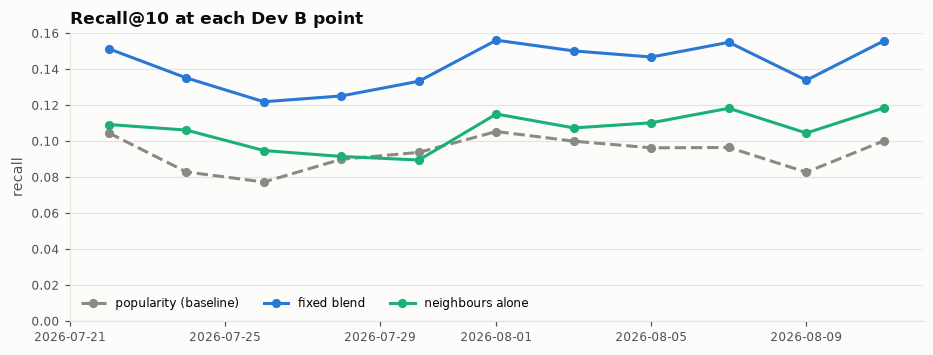

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.4))
plots.per_point_lines(ax, results)
ax.set_title("Recall@10 at each Dev B point")
plt.show()

## 4. Where does it help? By history size, without the head, and coverage

- **By history size:** accounts with 1, 2 to 4, and 5 or more tokens in the 14 days before $t$.
- **Without the head:** recall after removing from the target the most popular tokens that hold a third of the
  history's interactions (Cremonesi et al. 2010). A model cannot score here on popular tokens alone.
- **Coverage:** the share of all tokens that appear in at least one account's list.

In [13]:
columns = ["recall", "recall_1", "recall_2-4", "recall_5+", "recall_no_head", "coverage"]
pd.DataFrame({name: table[columns].mean() for name, table in results.items()}).T

,recall,recall_1,recall_2-4,recall_5+,recall_no_head,coverage
popularity (baseline),0.0936,0.1468,0.1085,0.0551,0.0000,0.0024
fixed blend,0.1422,0.2091,0.1572,0.0966,0.0303,0.0418
neighbours alone,0.1059,0.1347,0.1156,0.0848,0.0428,0.0561
